# Pan-cancer pooled ROC (pretrained three-head model)

Counterpart of `CODEX_hcc/Pred_statistic_visual_hcc_all.ipynb` **Pooled StarDist ROC**, but labels are the pan-cancer L1 / L12 / L2 ontology.

Both CV protocols are trained and predicted. Cross-section was retrained 2026-10-13 with P5CRC in the CV (896 slides). Cross-celltype is still the 2026-10-02 run (895 slides, no P5CRC).

| | cross-section | cross-celltype |
|--|--|--|
| train | `result_all_spatial/` | `result_cell_stratified_spatial/` |
| predict | `pred_all_spatial/` | `pred_cell_stratified_spatial/` |
| slides / cells | 896 / 5,627,071 | 895 / 5,510,950 |
| OOF L2 macro AUROC | 0.888 | 0.807 |

1. Early cells: pooled OvR ROC from **section-CV** `pred_all_spatial/stardist_roc/`.
2. Later cells: the same plots from **cell-stratified** `pred_cell_stratified_spatial/`, plus fold OOF and per-class deltas.
3. Hold-out cancers (Prostate) still need UNI matched h5ads.
4. Last section: UNI2 A3 `best_mlp_gpu.pt` scored on every training section (`pred_uni2_A3_bestmlp/`). That file is fold 0, so this is deployment, not the pooled OOF.

2026.10.26: `3_demo_pred.sh uni2 A3` now defaults to OOF and writes `pred_uni2_A3_bestmlp_paired_v2_seed42_oof` from `result_uni2_A3_adjacent_spatial_k8mean_gate_paired_v2_seed42`. The last section still reads the finished historical deployment above.

This notebook keeps the published UNI comparison in one place: cross-section and cross-celltype. UNI2 A0–A3 is a separate notebook, `2_Pred_statistic_visual_pancancer_uni2_ablation.ipynb`.

```bash
conda activate SeededNTM
bash code/PanCancer/demo.sh status
# bash code/PanCancer/demo.sh section predict
# bash code/PanCancer/demo.sh celltype predict
```


In [1]:
import sys
import warnings
from pathlib import Path

warnings.filterwarnings("ignore")

import pandas as pd

REPO = Path("/home/lingyu/ssd2/Python/Hist2Pheno")
PKG = REPO / "code" / "Hist2Pheno_pkg"
PAN = REPO / "code" / "PanCancer"
for p in (PKG, PAN):
    if str(p) not in sys.path:
        sys.path.insert(0, str(p))

from uni_label_cv_helpers import plot_pooled_stardist_tier_rocs

PRED = REPO / "data" / "PanCancer" / "pred_all_spatial"
ROC_ROOT = PRED / "stardist_roc"
OUT = PRED / "pooled_roc"
OUT.mkdir(parents=True, exist_ok=True)
print("ROC_ROOT", ROC_ROOT, "exists", ROC_ROOT.is_dir())
print("n sample dirs", len(list(ROC_ROOT.glob("*"))) if ROC_ROOT.is_dir() else 0)

met = PRED / "metrics_per_section.csv"
if met.is_file():
    df = pd.read_csv(met)
    print(df.groupby("dataset")[["macro_auc_L1_cells", "macro_auc_L12_cells", "macro_auc_L2_cells"]].mean())
    display(df.head())

ROC_ROOT /home/lingyu/ssd2/Python/Hist2Pheno/data/PanCancer/pred_all_spatial/stardist_roc exists True
n sample dirs 896
                macro_auc_L1_cells  macro_auc_L12_cells  macro_auc_L2_cells
dataset                                                                    
BRCA                      0.881023             0.842856            0.812740
CRC                       0.715273             0.723666            0.685956
GBM                       0.601802             0.618054            0.615394
GIST                      0.657196             0.636736            0.633945
HCC                       0.780690             0.763424            0.736299
Lung                      0.679295             0.689398            0.663905
LungIncomplete                 NaN                  NaN                 NaN
PDAC                      0.785030             0.772976            0.727920


,section_id,dataset,sample,n_matched,n_stardist_all,macro_auc_L1,macro_auc_L12,macro_auc_L2,panel,macro_auc_L1_cells,macro_auc_L12_cells,macro_auc_L2_cells
0,Lung::THD0008,Lung,THD0008,34402,113389,0.592774,0.621689,0.627714,/nobackup2/users/lingyu/Python/Hist2Pheno/data...,0.592774,0.621689,0.627714
1,Lung::THD0011,Lung,THD0011,22034,56677,0.582242,0.589581,0.568254,/nobackup2/users/lingyu/Python/Hist2Pheno/data...,0.582242,0.589581,0.568254
2,Lung::TILD117LA,Lung,TILD117LA,9304,75608,0.721852,0.754717,0.705328,/nobackup2/users/lingyu/Python/Hist2Pheno/data...,0.721852,0.754717,0.705328
3,Lung::TILD117MA1,Lung,TILD117MA1,8004,121456,0.785000,0.775589,0.723897,/nobackup2/users/lingyu/Python/Hist2Pheno/data...,0.785000,0.775589,0.723897
4,Lung::TILD175MA,Lung,TILD175MA,14132,72654,0.760221,0.777959,0.702635,/nobackup2/users/lingyu/Python/Hist2Pheno/data...,0.760221,0.777959,0.702635


## Pooled ROC (matched UNI cells, pan-cancer L1 / L12 / L2)

Uses the same CSV layout as cohort StarDist AUROC tables so `plot_pooled_stardist_tier_rocs` can concatenate all sections.



=== L2 | discovering validation_external_stardist_matched_AUROC.csv ===
  BRCA__rep1: 157,016 cells, 20 local classes
  BRCA__rep2: 107,180 cells, 20 local classes
  CRC__P1CRC: 149,492 cells, 20 local classes
  CRC__P2CRC: 202,900 cells, 20 local classes
  CRC__P5CRC: 116,121 cells, 20 local classes
  GBM__P174511_Initial: 35,961 cells, 20 local classes
  GBM__P179161_Recurrent: 135,055 cells, 20 local classes
  GIST__Charvill-94_c009_v001_r001_reg001: 5,257 cells, 20 local classes
  GIST__Charvill-94_c009_v001_r001_reg002: 3,098 cells, 20 local classes
  GIST__Charvill-94_c009_v001_r001_reg003: 8,740 cells, 20 local classes
  GIST__Charvill-94_c009_v001_r001_reg004: 12,062 cells, 20 local classes
  GIST__Charvill-94_c009_v001_r001_reg005: 4,090 cells, 20 local classes
  GIST__Charvill-94_c009_v001_r001_reg006: 5,225 cells, 20 local classes
  GIST__Charvill-94_c009_v001_r001_reg007: 10,544 cells, 20 local classes
  GIST__Charvill-94_c009_v001_r001_reg008: 6,964 cells, 20 local classe

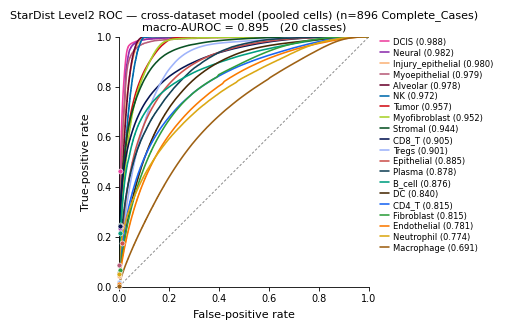

Pooled macro AUROC (L2): 0.8947

=== L12 | discovering validation_external_stardist_matched_AUROC_level12.csv ===
  BRCA__rep1: 157,016 cells, 8 local classes
  BRCA__rep2: 107,180 cells, 8 local classes
  CRC__P1CRC: 149,492 cells, 8 local classes
  CRC__P2CRC: 202,900 cells, 8 local classes
  CRC__P5CRC: 116,121 cells, 8 local classes
  GBM__P174511_Initial: 35,961 cells, 8 local classes
  GBM__P179161_Recurrent: 135,055 cells, 8 local classes
  GIST__Charvill-94_c009_v001_r001_reg001: 5,257 cells, 8 local classes
  GIST__Charvill-94_c009_v001_r001_reg002: 3,098 cells, 8 local classes
  GIST__Charvill-94_c009_v001_r001_reg003: 8,740 cells, 8 local classes
  GIST__Charvill-94_c009_v001_r001_reg004: 12,062 cells, 8 local classes
  GIST__Charvill-94_c009_v001_r001_reg005: 4,090 cells, 8 local classes
  GIST__Charvill-94_c009_v001_r001_reg006: 5,225 cells, 8 local classes
  GIST__Charvill-94_c009_v001_r001_reg007: 10,544 cells, 8 local classes
  GIST__Charvill-94_c009_v001_r001_reg008: 6

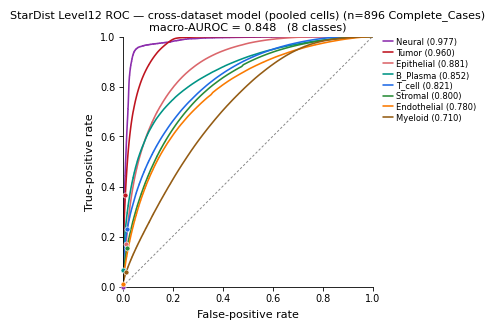

Pooled macro AUROC (L12): 0.8477

=== L1 | discovering validation_external_stardist_matched_AUROC_level1.csv ===
  BRCA__rep1: 157,016 cells, 5 local classes
  BRCA__rep2: 107,180 cells, 5 local classes
  CRC__P1CRC: 149,492 cells, 5 local classes
  CRC__P2CRC: 202,900 cells, 5 local classes
  CRC__P5CRC: 116,121 cells, 5 local classes
  GBM__P174511_Initial: 35,961 cells, 5 local classes
  GBM__P179161_Recurrent: 135,055 cells, 5 local classes
  GIST__Charvill-94_c009_v001_r001_reg001: 5,257 cells, 5 local classes
  GIST__Charvill-94_c009_v001_r001_reg002: 3,098 cells, 5 local classes
  GIST__Charvill-94_c009_v001_r001_reg003: 8,740 cells, 5 local classes
  GIST__Charvill-94_c009_v001_r001_reg004: 12,062 cells, 5 local classes
  GIST__Charvill-94_c009_v001_r001_reg005: 4,090 cells, 5 local classes
  GIST__Charvill-94_c009_v001_r001_reg006: 5,225 cells, 5 local classes
  GIST__Charvill-94_c009_v001_r001_reg007: 10,544 cells, 5 local classes
  GIST__Charvill-94_c009_v001_r001_reg008: 6,

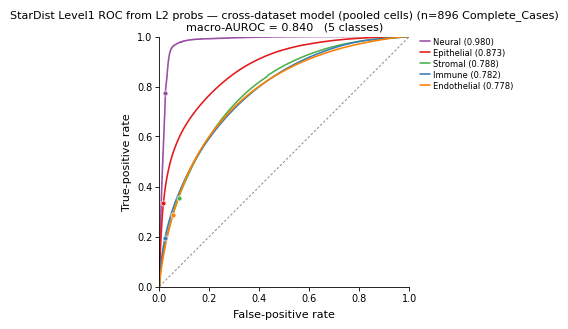

Pooled macro AUROC (L1): 0.8402
pooled L2 macro AUROC = 0.8947
pooled L12 macro AUROC = 0.8477
pooled L1 macro AUROC = 0.8402


In [2]:
if not ROC_ROOT.is_dir() or not any(ROC_ROOT.iterdir()):
    raise FileNotFoundError(
        f"No per-section AUROC CSVs under {ROC_ROOT}. "
        "Run code/PanCancer/PanCancer_predict_visualize.py first."
    )

results = plot_pooled_stardist_tier_rocs(
    ROC_ROOT,
    OUT,
    tiers=("l2", "l12", "l1"),
    layout="pooled_stardist",
    pan_organ="pancancer",
    figsize=(2.0, 2.0),
    show_barplot=False,
    save_per_class_csv=True,
    show=True,
)
for tier, rec in results.items():
    info = rec.get("roc_info") or {}
    print(f"pooled {tier.upper()} macro AUROC = {info.get('macro_auc', float('nan')):.4f}")

## Hold-out cancers (Prostate and others under `data/`)

Section-CV weights: `data/PanCancer/result_all_spatial/cross_dataset_cv/D_emph_L2_spatial_pancancer/best_mlp_gpu.pt`

Cell-stratified weights: `data/PanCancer/result_cell_stratified_spatial/cross_dataset_cv/D_emph_L2_spatial_pancancer_cellstrat/best_mlp_gpu.pt`

| Folder | Status |
|--------|--------|
| `data/ST/Prostate` | HE + StarDist; **no** `{sample}_matched_features.h5ad` yet |
| `data/Visium/Prostate` | Visium counts; needs HE alignment + UNI + h5ad |

Apply a pan-cancer checkpoint only after a matched UNI h5ad exists, then:

```bash
python -u code/PanCancer/PanCancer_predict_visualize.py \
  --checkpoint data/PanCancer/result_all_spatial/cross_dataset_cv/D_emph_L2_spatial_pancancer/best_mlp_gpu.pt \
  --index-csv /path/to/prostate_section_index.csv
```

Native labels (if any) should map through `celltype_pancancer` aliases, or leave GT empty and only inspect StarDist-all spatial maps.


## Cross-section vs cross-celltype (both complete)

Section-CV and cell-stratified CV use the same three-head spatial model (k=8). They differ only in how cells are split:

- **cross-section:** each HE section is wholly train or val (`GroupKFold` on section IDs).
- **cross-celltype:** `StratifiedKFold` on `L1|L12|L2`; cells from the same section can appear in both splits (spatial neighbors are split-masked). OOF is therefore optimistic vs a new slide.

Train 3b finished all 5 folds + `he_validate`; `demo.sh celltype predict` wrote 896 StarDist AUROC dirs. The cells below compare:

1. Fold OOF AUROC / F1 from `group_cv_folds.csv` (same estimator on both sides).
2. Per-dataset mean AUROC from `metrics_per_section.csv`.
3. Pooled StarDist ROC and per-class OvR AUROC (`pred_*/stardist_roc/`).


,protocol,best_mlp,n_fold_ckpt,pred_roc_dirs
0,cross-section,True,5,896
1,cross-celltype,True,5,896


,protocol,n_cells,n_folds,best_fold,oof_l2_macro_auc,cv_l2_macro_f1_mean
0,cross-section,5627071,5,0,0.888393,0.292099
1,cross-celltype,5627071,5,3,0.801286,0.101938


OOF L2 macro AUROC  section=0.8884  celltype=0.8013


,L1_section,L12_section,L2_section,L1_celltype,L12_celltype,L2_celltype
dataset,,,,,,
BRCA,0.881023,0.842856,0.812740,0.849170,0.828363,0.803004
CRC,0.715273,0.723666,0.685956,0.620933,0.604414,0.542350
GBM,0.601802,0.618054,0.615394,0.518234,0.519704,0.516080
GIST,0.657196,0.636736,0.633945,0.564669,0.558524,0.543127
HCC,0.780690,0.763424,0.736299,0.668534,0.668922,0.637586
Lung,0.679295,0.689398,0.663905,0.638661,0.637800,0.632082
LungIncomplete,NaN,NaN,NaN,NaN,NaN,NaN
PDAC,0.785030,0.772976,0.727920,0.664235,0.659841,0.625531


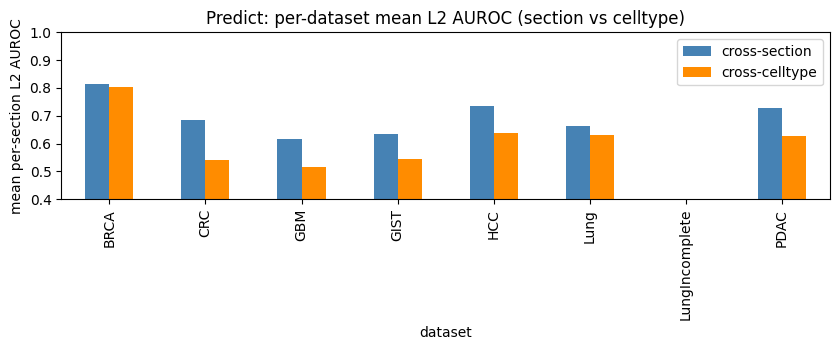

section OOF L2 ROC /home/lingyu/ssd2/Python/Hist2Pheno/data/PanCancer/result_all_spatial/roc_internal_level2_oof.png


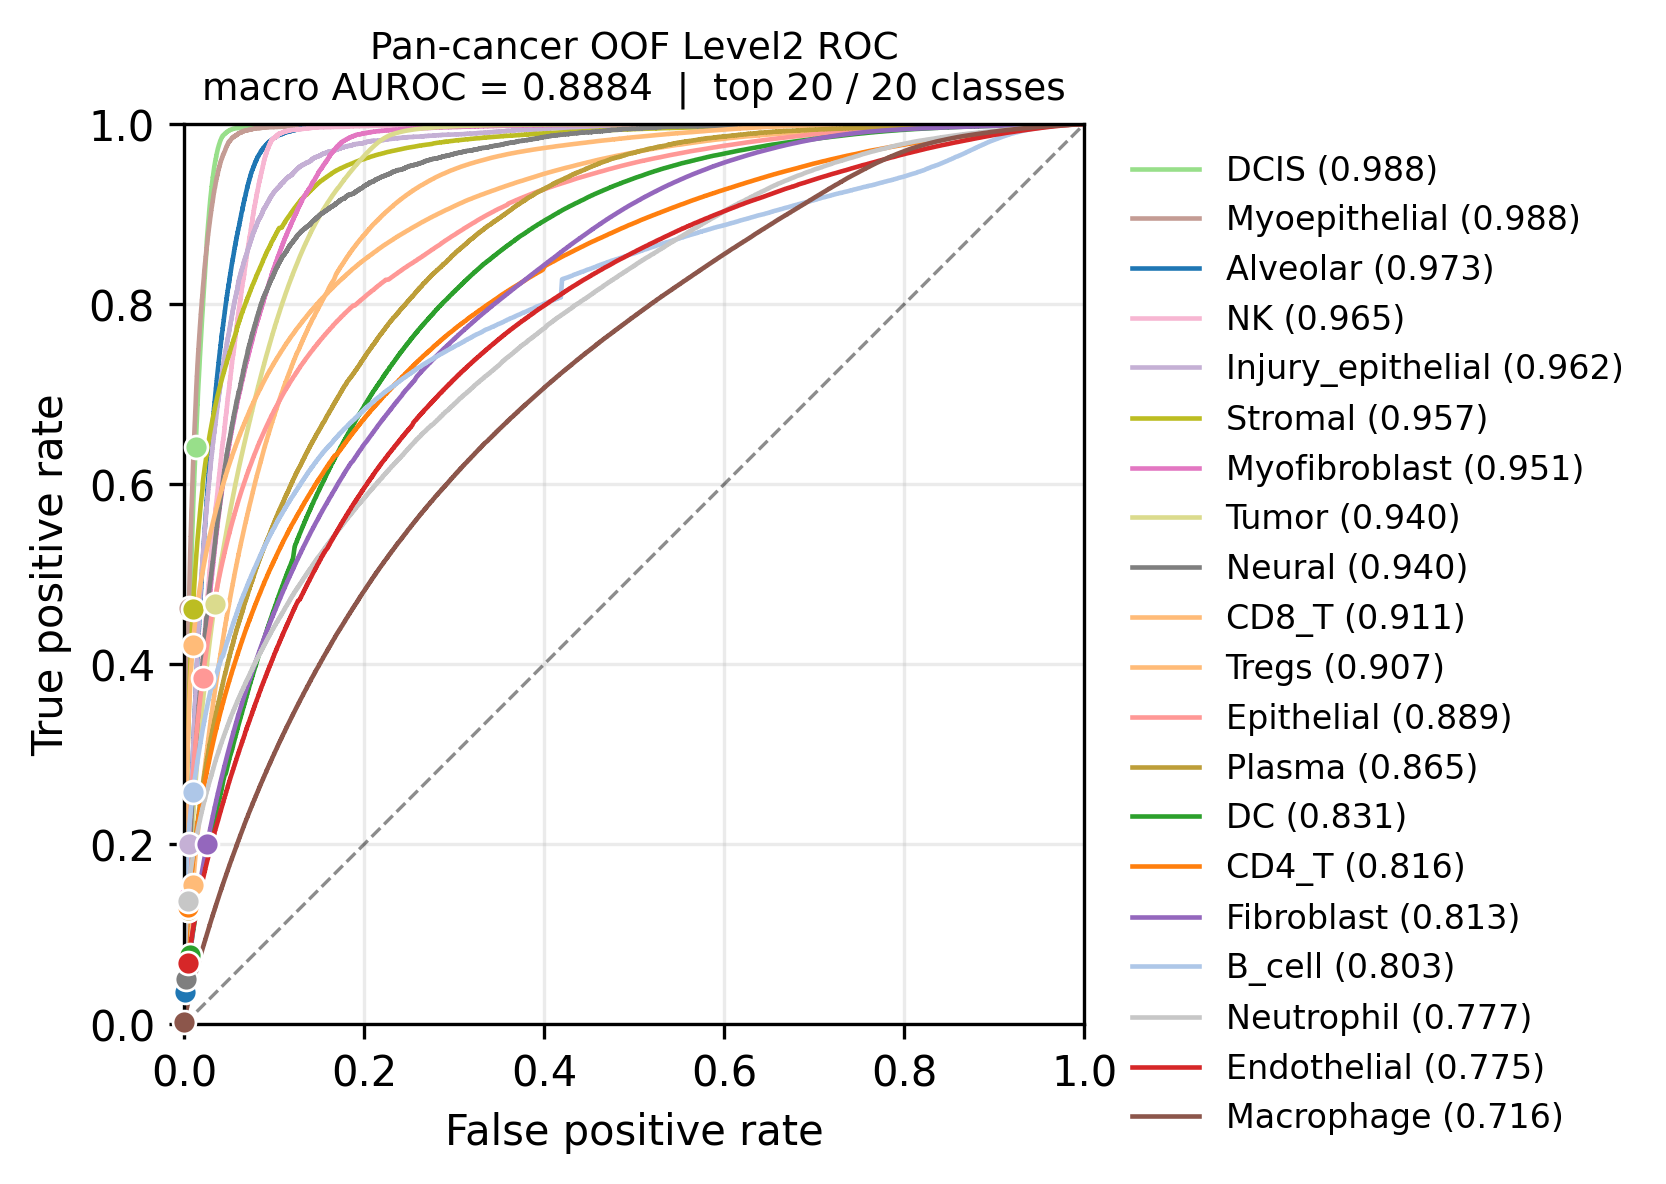

celltype OOF L2 ROC /home/lingyu/ssd2/Python/Hist2Pheno/data/PanCancer/result_cell_stratified_spatial/roc_internal_level2_oof.png


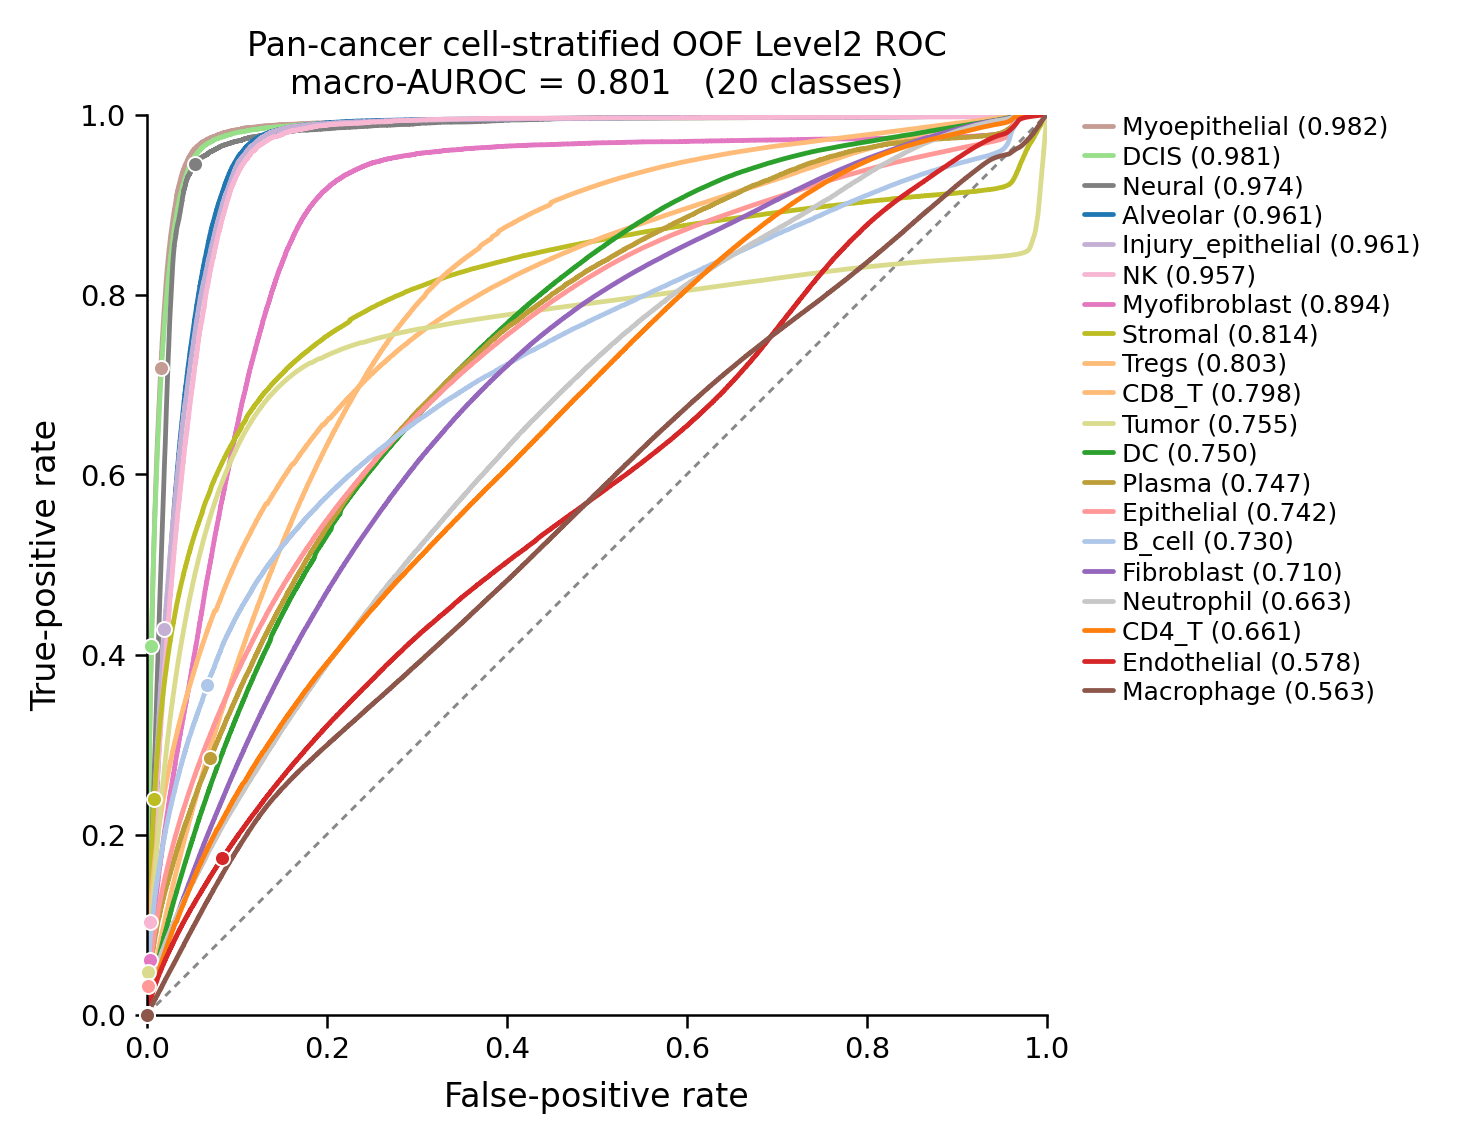

section OOF L2 confusion /home/lingyu/ssd2/Python/Hist2Pheno/data/PanCancer/result_all_spatial/conf_matrix_level2.png


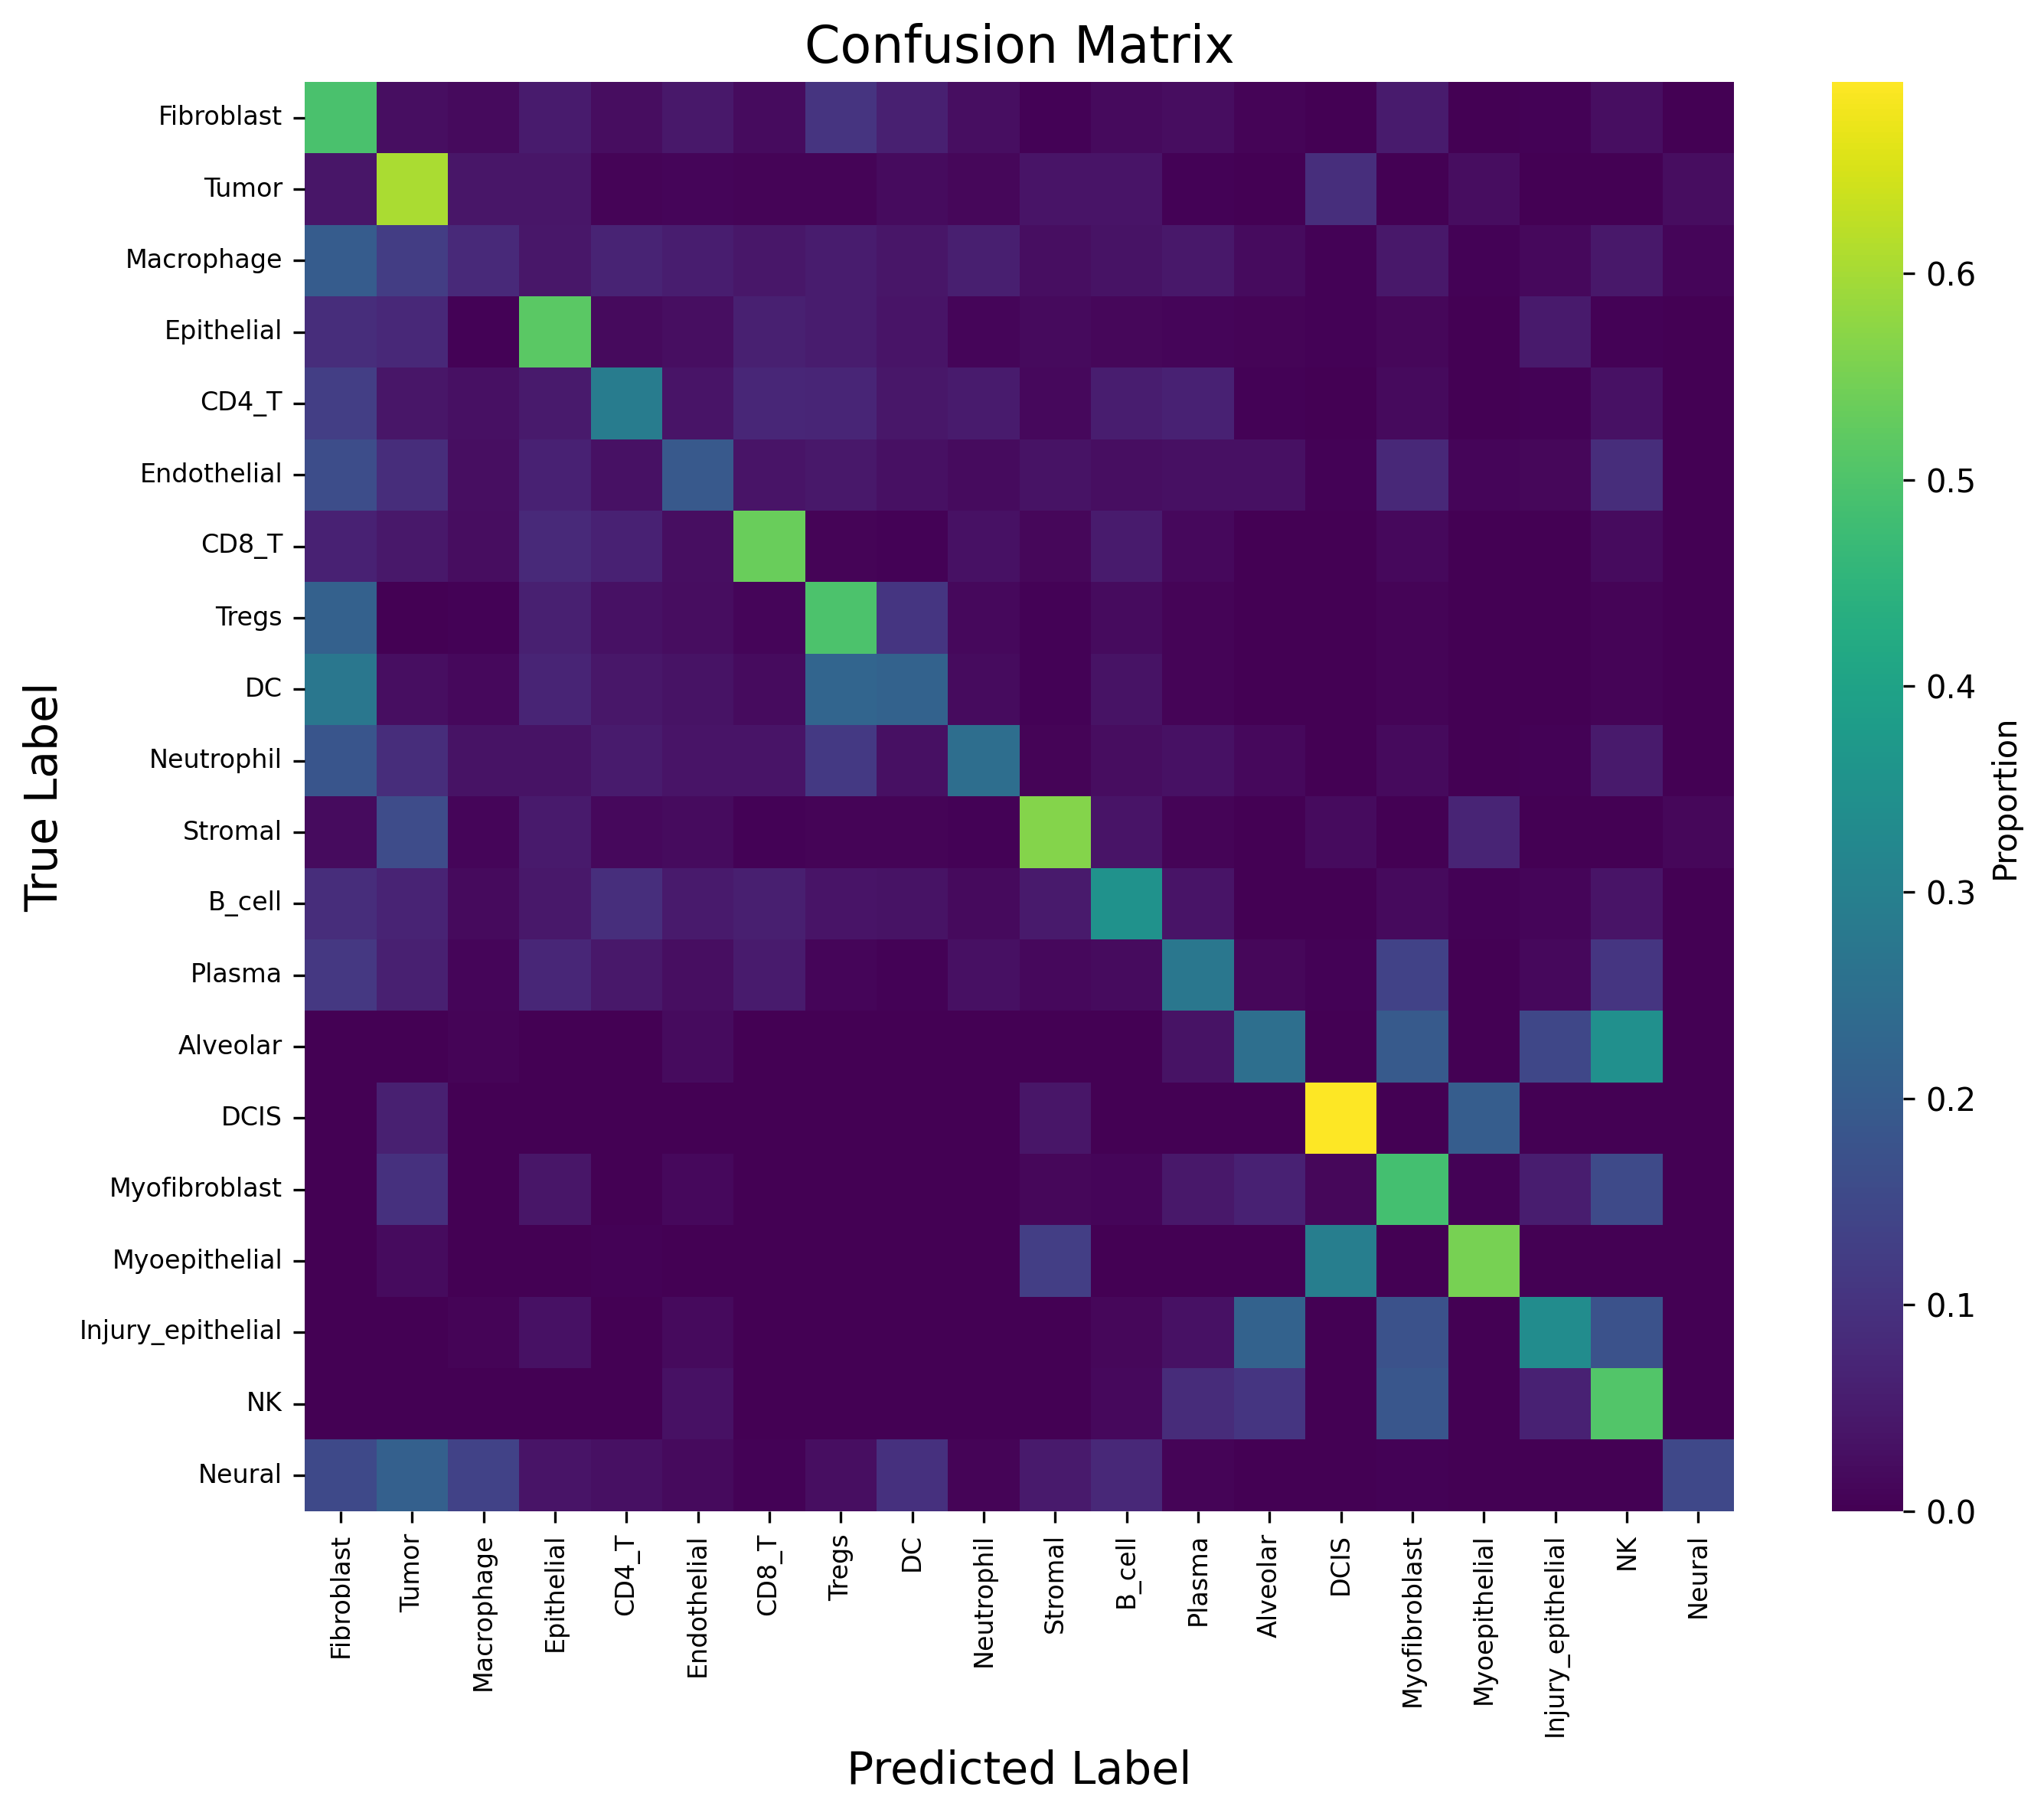

celltype OOF L2 confusion /home/lingyu/ssd2/Python/Hist2Pheno/data/PanCancer/result_cell_stratified_spatial/conf_matrix_level2.png


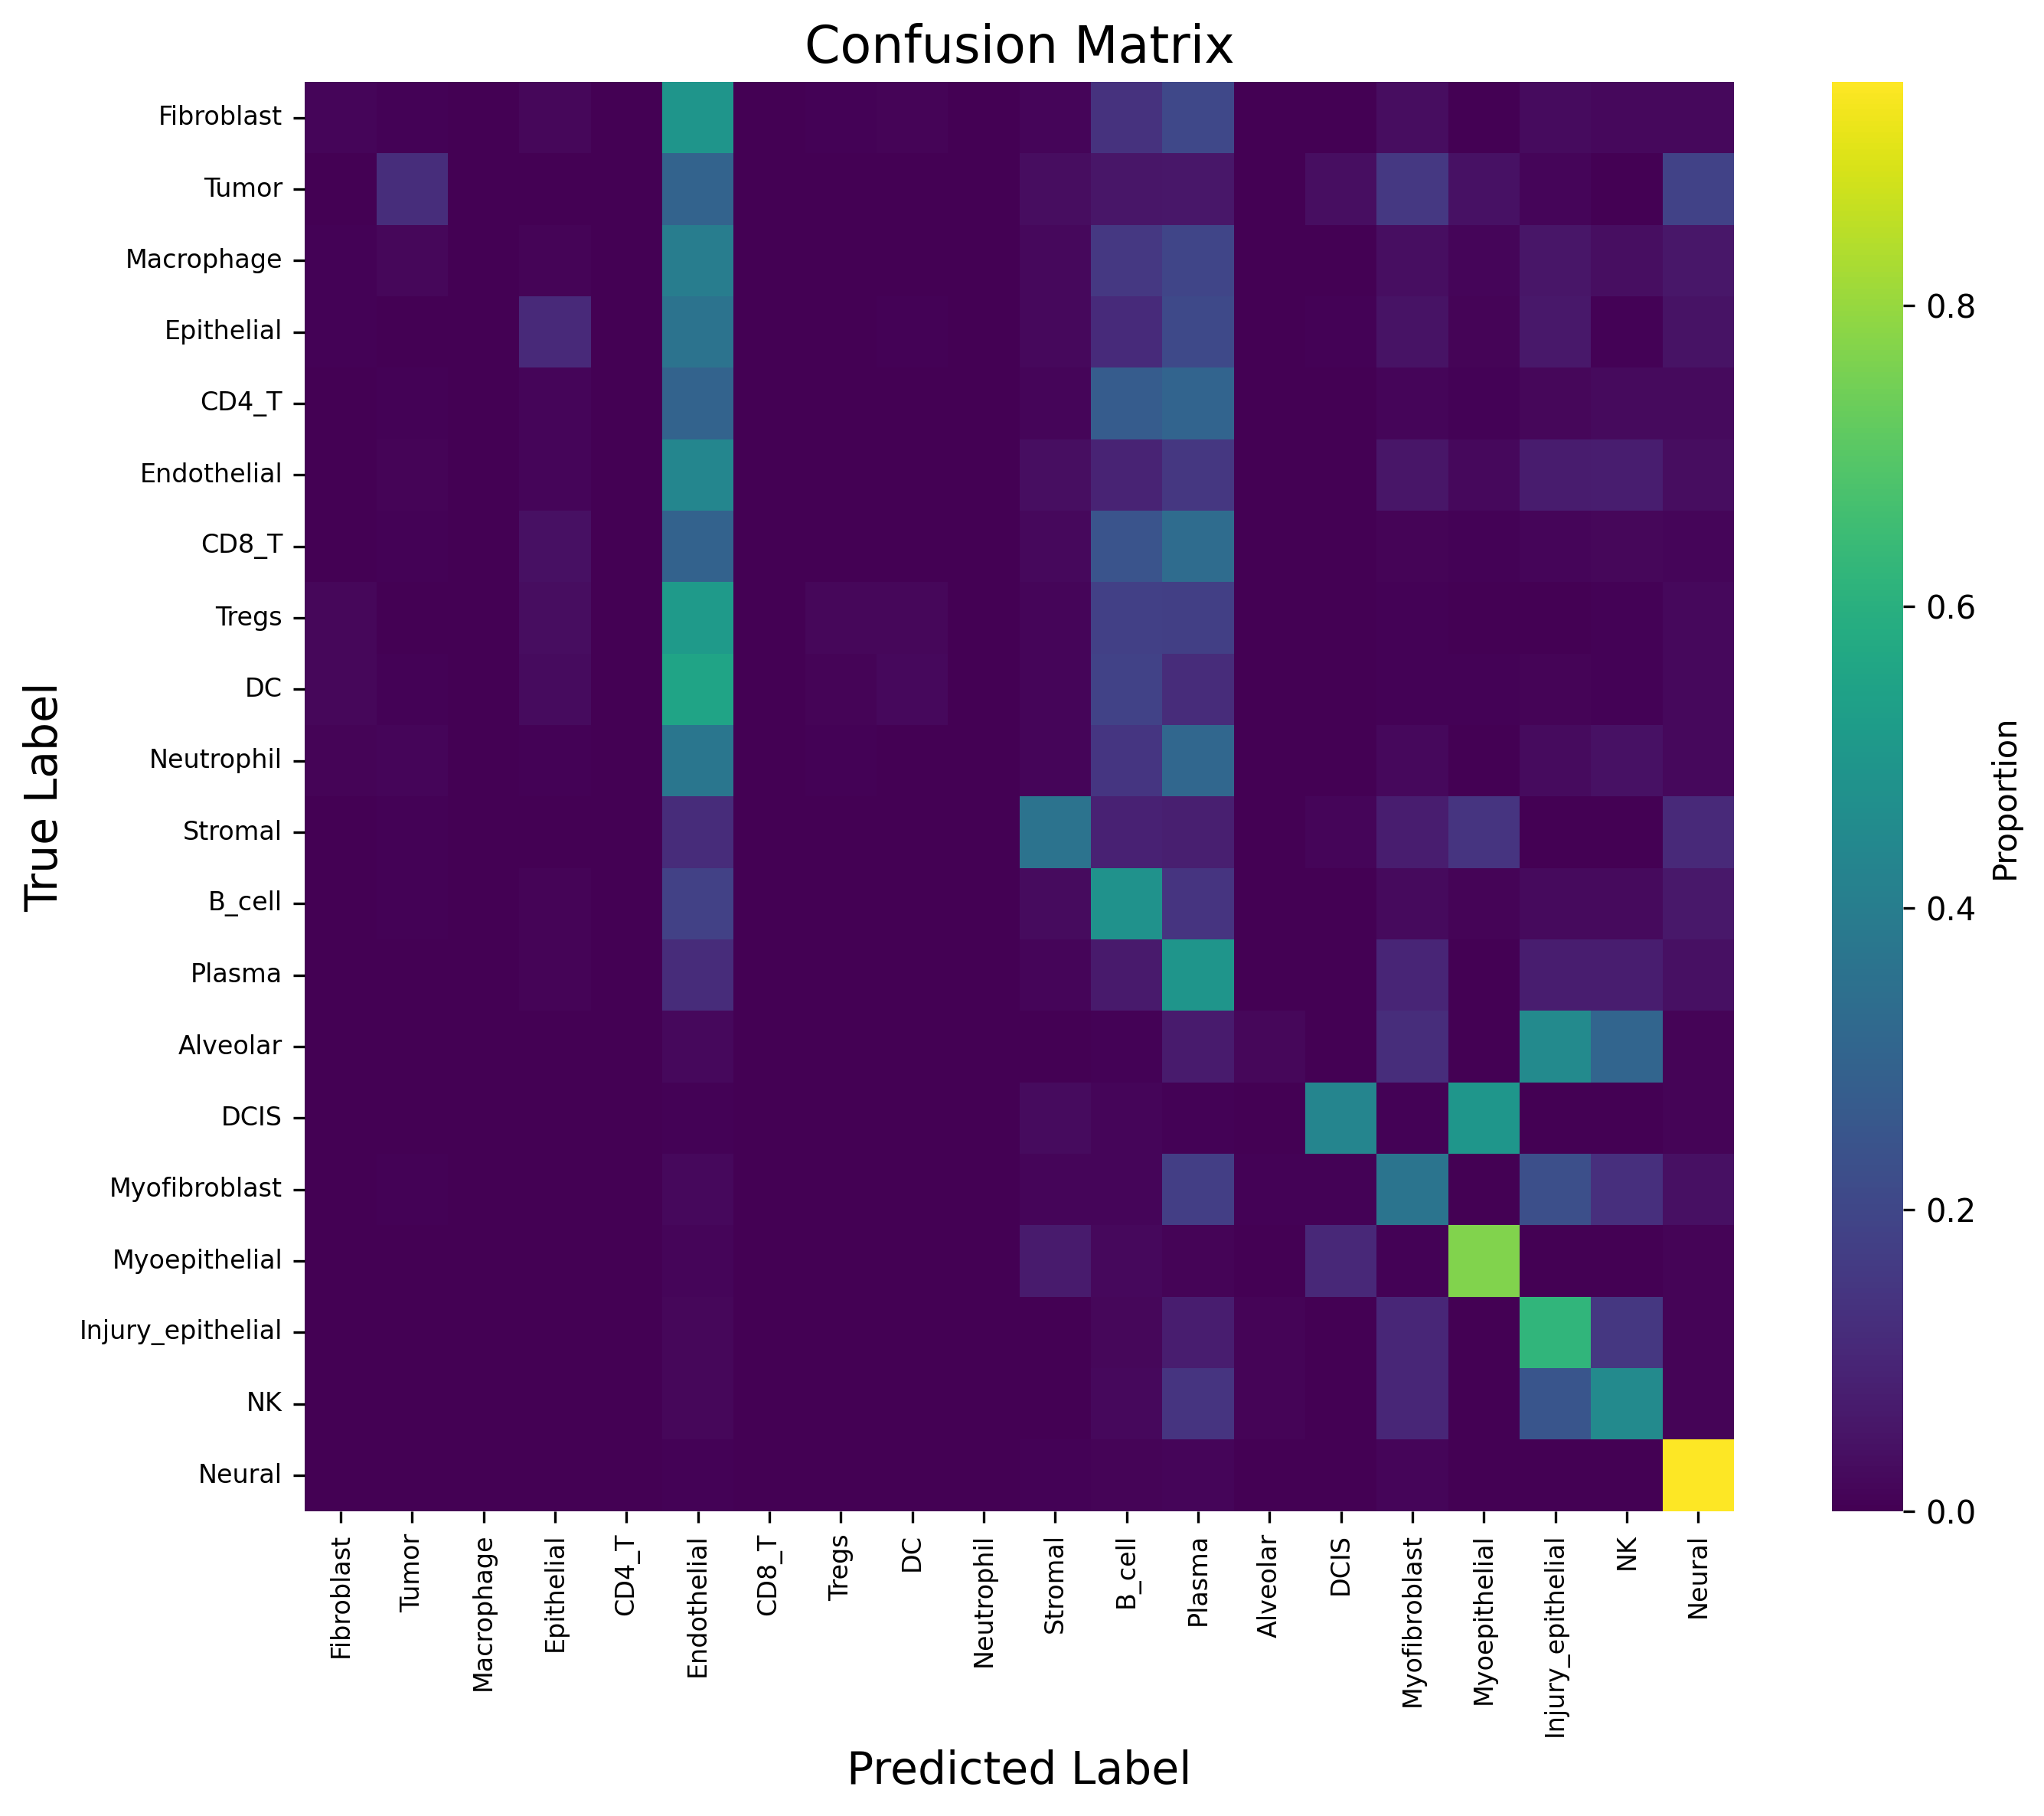

In [3]:
import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import Image, display

from pred_statistic_visual import n_sample_dirs

PRED_SECTION = REPO / "data" / "PanCancer" / "pred_all_spatial"
PRED_CELL = REPO / "data" / "PanCancer" / "pred_cell_stratified_spatial"
RES_SECTION = REPO / "data" / "PanCancer" / "result_all_spatial"
RES_CELL = REPO / "data" / "PanCancer" / "result_cell_stratified_spatial"
CKPT_SECTION = RES_SECTION / "cross_dataset_cv" / "D_emph_L2_spatial_pancancer"
CKPT_CELL = RES_CELL / "cross_dataset_cv" / "D_emph_L2_spatial_pancancer_cellstrat"
OUT_CMP = PRED_CELL / "pooled_roc"
OUT_CMP.mkdir(parents=True, exist_ok=True)


inv = pd.DataFrame(
    [
        {
            "protocol": "cross-section",
            "best_mlp": (CKPT_SECTION / "best_mlp_gpu.pt").is_file(),
            "n_fold_ckpt": len(list(CKPT_SECTION.glob("hce_group_fold_*.pt"))),
            "pred_roc_dirs": n_sample_dirs(PRED_SECTION),
        },
        {
            "protocol": "cross-celltype",
            "best_mlp": (CKPT_CELL / "best_mlp_gpu.pt").is_file(),
            "n_fold_ckpt": len(list(CKPT_CELL.glob("hce_group_fold_*.pt"))),
            "pred_roc_dirs": n_sample_dirs(PRED_CELL),
        },
    ]
)
display(inv)

oof_rows = []
for name, path in (
    ("cross-section", RES_SECTION / "validation_internal_metrics.csv"),
    ("cross-celltype", RES_CELL / "validation_internal_metrics.csv"),
):
    if path.is_file():
        row = pd.read_csv(path).iloc[0].to_dict()
        row["protocol"] = name
        oof_rows.append(row)
oof_sum = pd.DataFrame(oof_rows)
if not oof_sum.empty:
    cols = [c for c in ("protocol", "n_cells", "n_folds", "best_fold", "oof_l2_macro_auc", "cv_l2_macro_f1_mean") if c in oof_sum]
    display(oof_sum[cols])
    print(
        "OOF L2 macro AUROC  section={:.4f}  celltype={:.4f}".format(
            float(oof_sum.loc[oof_sum.protocol == "cross-section", "oof_l2_macro_auc"].iloc[0]),
            float(oof_sum.loc[oof_sum.protocol == "cross-celltype", "oof_l2_macro_auc"].iloc[0]),
        )
    )

auc_cols = ["macro_auc_L1_cells", "macro_auc_L12_cells", "macro_auc_L2_cells"]
ds_tabs = []
for name, pred in (("section", PRED_SECTION), ("celltype", PRED_CELL)):
    met = pred / "metrics_per_section.csv"
    if met.is_file():
        df = pd.read_csv(met)
        g = df.groupby("dataset")[auc_cols].mean()
        g.columns = [f"{c.replace('macro_auc_', '').replace('_cells', '')}_{name}" for c in g.columns]
        ds_tabs.append(g)
if ds_tabs:
    ds_cmp = ds_tabs[0].join(ds_tabs[1:], how="outer")
    display(ds_cmp)
    plot_cols = [c for c in ds_cmp.columns if c.startswith("L2_")]
    if plot_cols:
        ax = ds_cmp[plot_cols].plot(kind="bar", figsize=(8.5, 3.6), color=["steelblue", "darkorange"])
        ax.set_ylim(0.4, 1.0)
        ax.set_ylabel("mean per-section L2 AUROC")
        ax.set_title("Predict: per-dataset mean L2 AUROC (section vs celltype)")
        ax.legend(["cross-section", "cross-celltype"])
        plt.tight_layout()
        plt.show()

for title, path in (
    ("section OOF L2 ROC", RES_SECTION / "roc_internal_level2_oof.png"),
    ("celltype OOF L2 ROC", RES_CELL / "roc_internal_level2_oof.png"),
    ("section OOF L2 confusion", RES_SECTION / "conf_matrix_level2.png"),
    ("celltype OOF L2 confusion", RES_CELL / "conf_matrix_level2.png"),
):
    if path.is_file():
        print(title, path)
        display(Image(filename=str(path), width=520))


,fold,section_OOF_L1,section_OOF_L12,section_OOF_L2,section_OOF_sum,section_OOF_L2_f1,section_best_epoch,cell_OOF_L1,cell_OOF_L12,cell_OOF_L2,cell_OOF_sum,cell_OOF_L2_f1,cell_best_epoch
0,0,0.855409,0.856646,0.903856,2.615911,0.293737,4,0.723292,0.732661,0.796095,2.252049,0.097619,0
1,1,0.813139,0.811372,0.870913,2.495423,0.287483,12,0.724622,0.734694,0.797320,2.256636,0.094392,0
2,2,0.834711,0.830789,0.871047,2.536548,0.251782,8,0.727656,0.739166,0.801479,2.268302,0.100254,0
3,3,0.815737,0.834062,0.883107,2.532905,0.294302,24,0.728053,0.745886,0.808706,2.282645,0.109158,0
4,4,0.806103,0.819338,0.877650,2.503091,0.333193,11,0.728918,0.739992,0.804530,2.273440,0.108268,0


Fold OOF (full val after each fold). celltype best_epoch=0 on folds 0-3 is the resume placeholder; those folds still have OOF metrics.


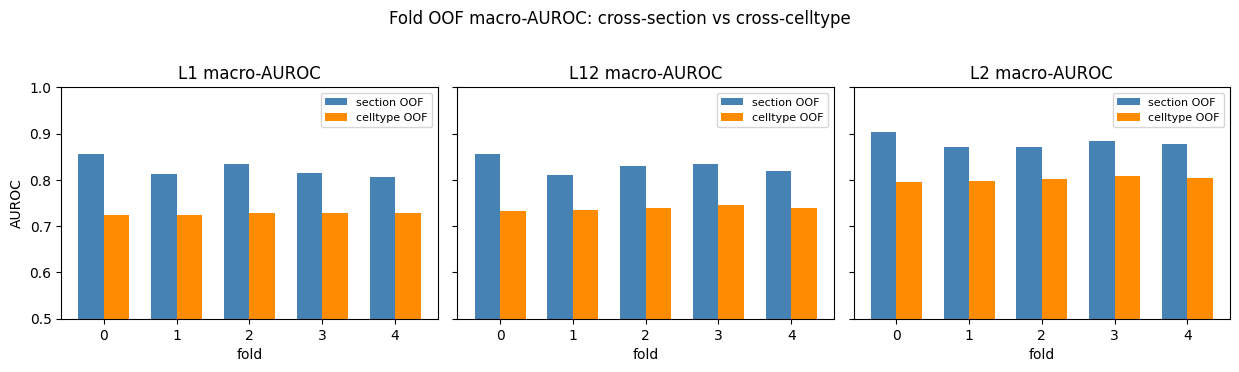

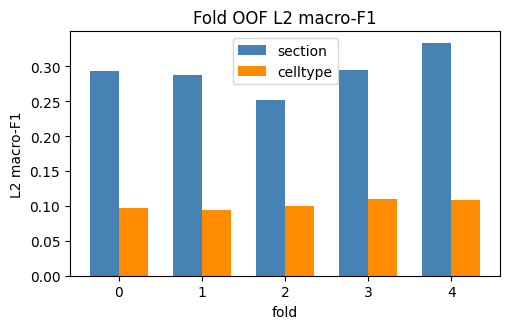

In [4]:
from pred_statistic_visual import load_fold_oof

cmp = pd.DataFrame({"fold": range(5)}).set_index("fold")
sec_csv = CKPT_SECTION / "group_cv_folds.csv"
cell_csv = CKPT_CELL / "group_cv_folds.csv"
if sec_csv.is_file():
    cmp = cmp.join(load_fold_oof(sec_csv, "section"))
if cell_csv.is_file():
    cmp = cmp.join(load_fold_oof(cell_csv, "cell"))
cmp = cmp.reset_index()
display(cmp)

print(
    "Fold OOF (full val after each fold). "
    "celltype best_epoch=0 on folds 0-3 is the resume placeholder; those folds still have OOF metrics."
)

fig, axes = plt.subplots(1, 3, figsize=(12.5, 3.6), sharey=True)
for ax, tier, scol, ccol in (
    (axes[0], "L1", "section_OOF_L1", "cell_OOF_L1"),
    (axes[1], "L12", "section_OOF_L12", "cell_OOF_L12"),
    (axes[2], "L2", "section_OOF_L2", "cell_OOF_L2"),
):
    x = cmp["fold"]
    w = 0.35
    if scol in cmp:
        ax.bar(x - w / 2, cmp[scol], width=w, label="section OOF", color="steelblue")
    if ccol in cmp:
        ax.bar(x + w / 2, cmp[ccol], width=w, label="celltype OOF", color="darkorange")
    ax.set_title(f"{tier} macro-AUROC")
    ax.set_xlabel("fold")
    ax.set_xticks(list(range(5)))
    ax.set_ylim(0.5, 1.0)
    ax.legend(fontsize=8)
axes[0].set_ylabel("AUROC")
fig.suptitle("Fold OOF macro-AUROC: cross-section vs cross-celltype", y=1.02)
fig.tight_layout()
plt.show()

if {"section_OOF_L2_f1", "cell_OOF_L2_f1"} <= set(cmp.columns):
    fig, ax = plt.subplots(figsize=(5.2, 3.4))
    ax.bar(cmp["fold"] - 0.175, cmp["section_OOF_L2_f1"], width=0.35, label="section", color="steelblue")
    ax.bar(cmp["fold"] + 0.175, cmp["cell_OOF_L2_f1"], width=0.35, label="celltype", color="darkorange")
    ax.set_xticks(list(range(5)))
    ax.set_xlabel("fold")
    ax.set_ylabel("L2 macro-F1")
    ax.set_title("Fold OOF L2 macro-F1")
    ax.legend()
    fig.tight_layout()
    plt.show()



=== L2 | discovering validation_external_stardist_matched_AUROC.csv ===
  BRCA__rep1: 157,016 cells, 20 local classes
  BRCA__rep2: 107,180 cells, 20 local classes
  CRC__P1CRC: 149,492 cells, 20 local classes
  CRC__P2CRC: 202,900 cells, 20 local classes
  CRC__P5CRC: 116,121 cells, 20 local classes
  GBM__P174511_Initial: 35,961 cells, 20 local classes
  GBM__P179161_Recurrent: 135,055 cells, 20 local classes
  GIST__Charvill-94_c009_v001_r001_reg001: 5,257 cells, 20 local classes
  GIST__Charvill-94_c009_v001_r001_reg002: 3,098 cells, 20 local classes
  GIST__Charvill-94_c009_v001_r001_reg003: 8,740 cells, 20 local classes
  GIST__Charvill-94_c009_v001_r001_reg004: 12,062 cells, 20 local classes
  GIST__Charvill-94_c009_v001_r001_reg005: 4,090 cells, 20 local classes
  GIST__Charvill-94_c009_v001_r001_reg006: 5,225 cells, 20 local classes
  GIST__Charvill-94_c009_v001_r001_reg007: 10,544 cells, 20 local classes
  GIST__Charvill-94_c009_v001_r001_reg008: 6,964 cells, 20 local classe

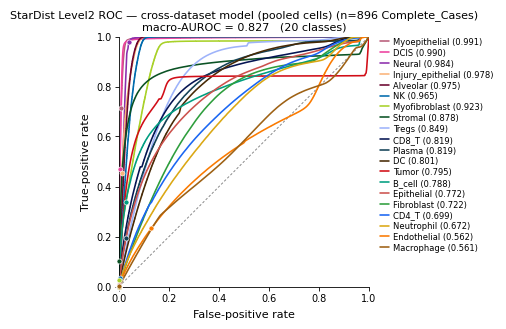

Pooled macro AUROC (L2): 0.8272

=== L12 | discovering validation_external_stardist_matched_AUROC_level12.csv ===
  BRCA__rep1: 157,016 cells, 8 local classes
  BRCA__rep2: 107,180 cells, 8 local classes
  CRC__P1CRC: 149,492 cells, 8 local classes
  CRC__P2CRC: 202,900 cells, 8 local classes
  CRC__P5CRC: 116,121 cells, 8 local classes
  GBM__P174511_Initial: 35,961 cells, 8 local classes
  GBM__P179161_Recurrent: 135,055 cells, 8 local classes
  GIST__Charvill-94_c009_v001_r001_reg001: 5,257 cells, 8 local classes
  GIST__Charvill-94_c009_v001_r001_reg002: 3,098 cells, 8 local classes
  GIST__Charvill-94_c009_v001_r001_reg003: 8,740 cells, 8 local classes
  GIST__Charvill-94_c009_v001_r001_reg004: 12,062 cells, 8 local classes
  GIST__Charvill-94_c009_v001_r001_reg005: 4,090 cells, 8 local classes
  GIST__Charvill-94_c009_v001_r001_reg006: 5,225 cells, 8 local classes
  GIST__Charvill-94_c009_v001_r001_reg007: 10,544 cells, 8 local classes
  GIST__Charvill-94_c009_v001_r001_reg008: 6

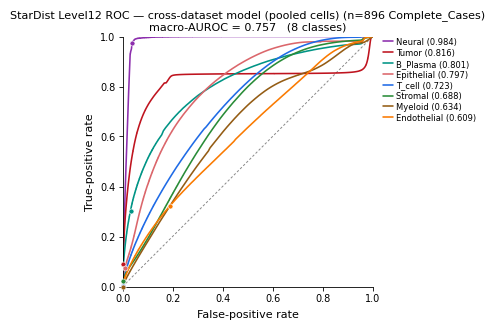

Pooled macro AUROC (L12): 0.7566

=== L1 | discovering validation_external_stardist_matched_AUROC_level1.csv ===
  BRCA__rep1: 157,016 cells, 5 local classes
  BRCA__rep2: 107,180 cells, 5 local classes
  CRC__P1CRC: 149,492 cells, 5 local classes
  CRC__P2CRC: 202,900 cells, 5 local classes
  CRC__P5CRC: 116,121 cells, 5 local classes
  GBM__P174511_Initial: 35,961 cells, 5 local classes
  GBM__P179161_Recurrent: 135,055 cells, 5 local classes
  GIST__Charvill-94_c009_v001_r001_reg001: 5,257 cells, 5 local classes
  GIST__Charvill-94_c009_v001_r001_reg002: 3,098 cells, 5 local classes
  GIST__Charvill-94_c009_v001_r001_reg003: 8,740 cells, 5 local classes
  GIST__Charvill-94_c009_v001_r001_reg004: 12,062 cells, 5 local classes
  GIST__Charvill-94_c009_v001_r001_reg005: 4,090 cells, 5 local classes
  GIST__Charvill-94_c009_v001_r001_reg006: 5,225 cells, 5 local classes
  GIST__Charvill-94_c009_v001_r001_reg007: 10,544 cells, 5 local classes
  GIST__Charvill-94_c009_v001_r001_reg008: 6,

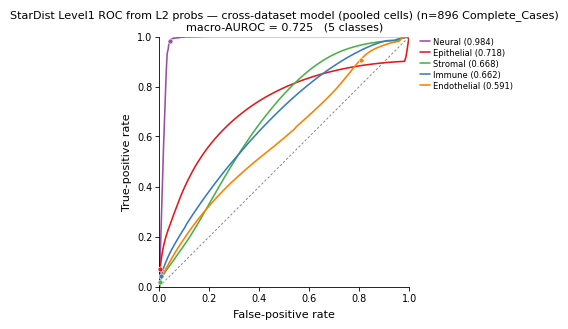

Pooled macro AUROC (L1): 0.7246
=== pooled macro AUROC (same estimator as the section plots above) ===
cross-section    L2   0.8946823988003292
cross-section    L12  0.8477393495235448
cross-section    L1   0.8401971701557475
cross-celltype   L2   0.8271586487220702
cross-celltype   L12  0.7565744210499856
cross-celltype   L1   0.7246136900583487


In [5]:
ROC_ROOT_CELL = PRED_CELL / "stardist_roc"
if not ROC_ROOT_CELL.is_dir() or not any(ROC_ROOT_CELL.iterdir()):
    raise FileNotFoundError(
        f"No per-section AUROC CSVs under {ROC_ROOT_CELL}. "
        "Run: bash code/PanCancer/demo.sh celltype predict"
    )

results_cell = plot_pooled_stardist_tier_rocs(
    ROC_ROOT_CELL,
    OUT_CMP,
    tiers=("l2", "l12", "l1"),
    layout="pooled_stardist",
    pan_organ="pancancer",
    figsize=(2.0, 2.0),
    show_barplot=False,
    save_per_class_csv=True,
    show=True,
)

print("=== pooled macro AUROC (same estimator as the section plots above) ===")
_section_results = results if "results" in dir() else {}
for proto, recs, src in (
    ("cross-section", _section_results, PRED_SECTION / "pooled_roc"),
    ("cross-celltype", results_cell, OUT_CMP),
):
    for tier in ("l2", "l12", "l1"):
        rec = (recs or {}).get(tier) or {}
        info = rec.get("roc_info") or {}
        auc = info.get("macro_auc")
        if auc is None:
            csv = src / f"roc_stardist_{tier}_cross_dataset_all_Complete_Cases_per_class_auc.csv"
            if csv.is_file():
                auc = float(pd.read_csv(csv)["auc_ovr"].mean())
        print(f"{proto:16s} {tier.upper():3s}  {auc}")



=== L2 per-class pooled OvR AUROC ===


,class_name,auc_section,n_pos_section,auc_cell,n_pos_cell,delta_cell_minus_section
3,Myoepithelial,0.979241,18010,0.990551,18010,0.011310
0,DCIS,0.987662,41775,0.989514,41775,0.001852
1,Neural,0.982206,10848,0.983876,10848,0.001670
2,Injury_epithelial,0.979751,14090,0.978381,14090,-0.001370
4,Alveolar,0.978058,58050,0.975020,58050,-0.003037
5,NK,0.971632,11655,0.964699,11655,-0.006933
7,Myofibroblast,0.952294,38977,0.922784,38977,-0.029510
14,DC,0.839909,316538,0.801295,316538,-0.038614
10,Tregs,0.901332,322139,0.848950,322139,-0.052383
12,Plasma,0.878341,61271,0.818679,61271,-0.059662


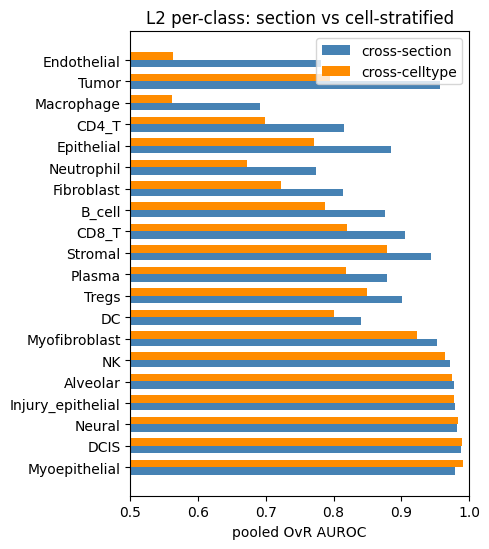


=== L12 per-class pooled OvR AUROC ===


,class_name,auc_section,n_pos_section,auc_cell,n_pos_cell,delta_cell_minus_section
0,Neural,0.977111,10848,0.983740,10848,0.006629
3,B_Plasma,0.851757,197065,0.800719,197065,-0.051038
7,Myeloid,0.710408,1180381,0.634364,1180381,-0.076043
2,Epithelial,0.880752,647123,0.796734,647123,-0.084018
4,T_cell,0.820984,1215636,0.723388,1215636,-0.097596
5,Stromal,0.800253,1048592,0.687909,1048592,-0.112344
1,Tumor,0.960311,882379,0.816398,882379,-0.143912
6,Endothelial,0.780338,445047,0.609342,445047,-0.170996


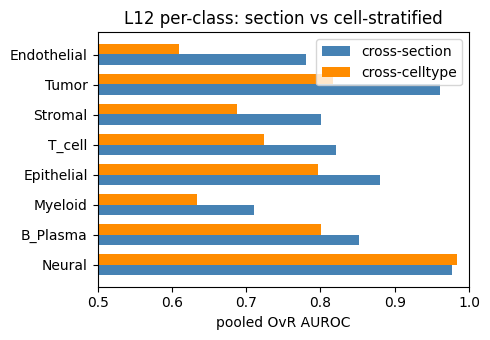


=== L1 per-class pooled OvR AUROC ===


,class_name,auc_section,n_pos_section,auc_cell,n_pos_cell,delta_cell_minus_section
0,Neural,0.979875,10848,0.983680,10848,0.003805
2,Stromal,0.787782,1048592,0.668069,1048592,-0.119713
3,Immune,0.782229,2593082,0.662144,2593082,-0.120085
1,Epithelial,0.872983,1529502,0.717901,1529502,-0.155082
4,Endothelial,0.778117,445047,0.591275,445047,-0.186843


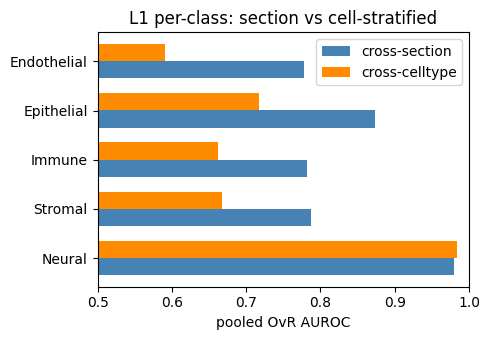

In [6]:
from pred_statistic_visual import load_per_class

sec_pool = PRED_SECTION / "pooled_roc"
cell_pool = OUT_CMP
any_cmp = False
for tier in ("l2", "l12", "l1"):
    a = load_per_class(sec_pool, tier)
    b = load_per_class(cell_pool, tier)
    if a is None or b is None:
        print(f"{tier.upper()}: need both per-class CSVs (section exists={a is not None}, cell={b is not None})")
        continue
    any_cmp = True
    m = a.merge(b, on="class_name", suffixes=("_section", "_cell"))
    m["delta_cell_minus_section"] = m["auc_cell"] - m["auc_section"]
    m = m.sort_values("delta_cell_minus_section", ascending=False)
    print(f"\n=== {tier.upper()} per-class pooled OvR AUROC ===")
    display(m)
    fig, ax = plt.subplots(figsize=(5.0, max(3.5, 0.28 * len(m))))
    y = range(len(m))
    ax.barh(list(y), m["auc_section"], height=0.35, label="cross-section", color="steelblue")
    ax.barh([i + 0.35 for i in y], m["auc_cell"], height=0.35, label="cross-celltype", color="darkorange")
    ax.set_yticks([i + 0.17 for i in y], m["class_name"])
    ax.set_xlim(0.5, 1.0)
    ax.set_xlabel("pooled OvR AUROC")
    ax.set_title(f"{tier.upper()} per-class: section vs cell-stratified")
    ax.legend()
    fig.tight_layout()
    fig.savefig(OUT_CMP / f"compare_{tier}_per_class_auc_section_vs_cellstrat.png", dpi=150)
    plt.show()

if not any_cmp:
    print("Run the previous cell first so celltype pooled per-class CSVs exist.")


## UNI2 A3 best_mlp on all training datasets

Checkpoint: `result_uni2_A3_adjacent_spatial_k8mean_gate/.../best_mlp_gpu.pt` (fold 0). One weight scores every section in `section_index.csv`. This is deployment, not the five-model pooled OOF (A3 OOF L2 macro AUROC 0.8907).

Fold 0's 182 sections were held out of this weight. The other sections were in its training set, so the all-dataset number is higher than performance on a new cohort. The second cell pools only the held-out sections.

Matched GT cells use the UNI2 cache. All-nuclei StarDist maps are skipped until `ImgEmbeddings_all_stardist/sc_pth_14_14` exists. The ROC tables do not need them.

```bash
export CUDA_DEVICE=0
unset CUDA_VISIBLE_DEVICES
export HIST2PHENO_CONTEXT_CACHE="$PWD/data/PanCancer/context_cache"
conda run --no-capture-output -n SeededNTM python -u \
  code/PanCancer/PanCancer_predict_visualize.py \
  --cuda-device "$CUDA_DEVICE" --embedder uni2 --deployment --spatial-k 8 \
  --skip-figures --skip-existing \
  --checkpoint data/PanCancer/result_uni2_A3_adjacent_spatial_k8mean_gate/cross_dataset_cv/A3_adjacent_spatial_k8mean_gate/best_mlp_gpu.pt \
  --pred-root data/PanCancer/pred_uni2_A3_bestmlp
```

2026.10.26: the command above is the finished historical deployment and is what the next cells plot. A new `bash code/PanCancer/3_demo_pred.sh uni2 A3` instead writes OOF predictions under `pred_uni2_A3_bestmlp_paired_v2_seed42_oof`, using the retrained checkpoint `result_uni2_A3_adjacent_spatial_k8mean_gate_paired_v2_seed42`. Pass `PREDICTION_MODE=deployment` to score one weight on every section.


A3 best_mlp ROC dirs 896/896
Mean of per-section AUROCs. The pooled number is printed under the ROC.


,n_matched,mean_section_L1,mean_section_L12,mean_section_L2
dataset,,,,
BRCA,264196,0.907005,0.891143,0.879239
CRC,468513,0.764516,0.785488,0.767571
GBM,171016,0.629853,0.650148,0.648114
GIST,1693169,0.697865,0.673637,0.666235
HCC,1059094,0.803411,0.783644,0.760199
Lung,578077,0.721648,0.727286,0.717292
PDAC,1393006,0.824739,0.811143,0.767284



=== L2 | discovering validation_external_stardist_matched_AUROC.csv ===
  BRCA__rep1: 157,016 cells, 20 local classes
  BRCA__rep2: 107,180 cells, 20 local classes
  CRC__P1CRC: 149,492 cells, 20 local classes
  CRC__P2CRC: 202,900 cells, 20 local classes
  CRC__P5CRC: 116,121 cells, 20 local classes
  GBM__P174511_Initial: 35,961 cells, 20 local classes
  GBM__P179161_Recurrent: 135,055 cells, 20 local classes
  GIST__Charvill-94_c009_v001_r001_reg001: 5,257 cells, 20 local classes
  GIST__Charvill-94_c009_v001_r001_reg002: 3,098 cells, 20 local classes
  GIST__Charvill-94_c009_v001_r001_reg003: 8,740 cells, 20 local classes
  GIST__Charvill-94_c009_v001_r001_reg004: 12,062 cells, 20 local classes
  GIST__Charvill-94_c009_v001_r001_reg005: 4,090 cells, 20 local classes
  GIST__Charvill-94_c009_v001_r001_reg006: 5,225 cells, 20 local classes
  GIST__Charvill-94_c009_v001_r001_reg007: 10,544 cells, 20 local classes
  GIST__Charvill-94_c009_v001_r001_reg008: 6,964 cells, 20 local classe

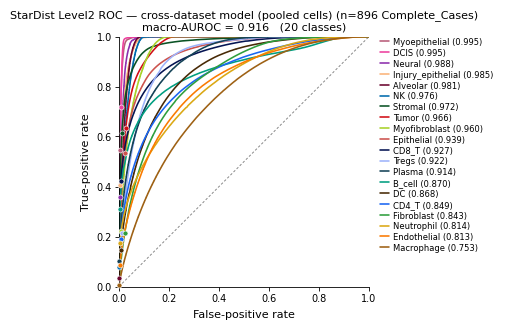

Pooled macro AUROC (L2): 0.9164

=== L12 | discovering validation_external_stardist_matched_AUROC_level12.csv ===
  BRCA__rep1: 157,016 cells, 8 local classes
  BRCA__rep2: 107,180 cells, 8 local classes
  CRC__P1CRC: 149,492 cells, 8 local classes
  CRC__P2CRC: 202,900 cells, 8 local classes
  CRC__P5CRC: 116,121 cells, 8 local classes
  GBM__P174511_Initial: 35,961 cells, 8 local classes
  GBM__P179161_Recurrent: 135,055 cells, 8 local classes
  GIST__Charvill-94_c009_v001_r001_reg001: 5,257 cells, 8 local classes
  GIST__Charvill-94_c009_v001_r001_reg002: 3,098 cells, 8 local classes
  GIST__Charvill-94_c009_v001_r001_reg003: 8,740 cells, 8 local classes
  GIST__Charvill-94_c009_v001_r001_reg004: 12,062 cells, 8 local classes
  GIST__Charvill-94_c009_v001_r001_reg005: 4,090 cells, 8 local classes
  GIST__Charvill-94_c009_v001_r001_reg006: 5,225 cells, 8 local classes
  GIST__Charvill-94_c009_v001_r001_reg007: 10,544 cells, 8 local classes
  GIST__Charvill-94_c009_v001_r001_reg008: 6

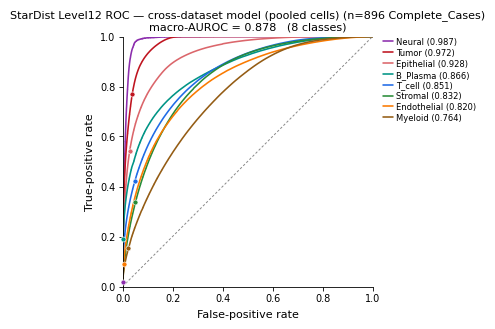

Pooled macro AUROC (L12): 0.8776

=== L1 | discovering validation_external_stardist_matched_AUROC_level1.csv ===
  BRCA__rep1: 157,016 cells, 5 local classes
  BRCA__rep2: 107,180 cells, 5 local classes
  CRC__P1CRC: 149,492 cells, 5 local classes
  CRC__P2CRC: 202,900 cells, 5 local classes
  CRC__P5CRC: 116,121 cells, 5 local classes
  GBM__P174511_Initial: 35,961 cells, 5 local classes
  GBM__P179161_Recurrent: 135,055 cells, 5 local classes
  GIST__Charvill-94_c009_v001_r001_reg001: 5,257 cells, 5 local classes
  GIST__Charvill-94_c009_v001_r001_reg002: 3,098 cells, 5 local classes
  GIST__Charvill-94_c009_v001_r001_reg003: 8,740 cells, 5 local classes
  GIST__Charvill-94_c009_v001_r001_reg004: 12,062 cells, 5 local classes
  GIST__Charvill-94_c009_v001_r001_reg005: 4,090 cells, 5 local classes
  GIST__Charvill-94_c009_v001_r001_reg006: 5,225 cells, 5 local classes
  GIST__Charvill-94_c009_v001_r001_reg007: 10,544 cells, 5 local classes
  GIST__Charvill-94_c009_v001_r001_reg008: 6,

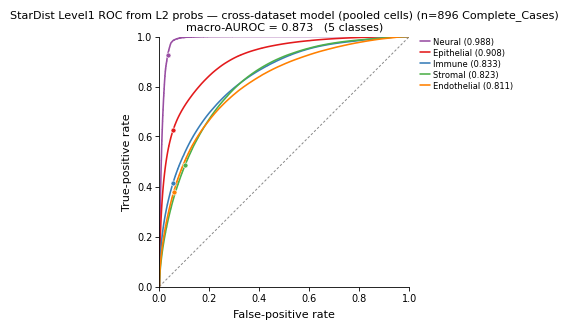

Pooled macro AUROC (L1): 0.8727
A3 best_mlp all-sections pooled L2 macro AUROC = 0.9164
A3 best_mlp all-sections pooled L12 macro AUROC = 0.8776
A3 best_mlp all-sections pooled L1 macro AUROC = 0.8727


In [7]:
# 2026.10.26, historical deployment / 新脚本默认写 pred_uni2_A3_bestmlp_paired_v2_seed42_oof，这里仍读已完成的旧目录
A3_PRED = REPO / "data" / "PanCancer" / "pred_uni2_A3_bestmlp"
A3_ROC = A3_PRED / "stardist_roc"
A3_OUT = A3_PRED / "pooled_roc"
A3_OUT.mkdir(parents=True, exist_ok=True)
n_index = 896
n_done = len([p for p in A3_ROC.iterdir() if p.is_dir()]) if A3_ROC.is_dir() else 0
print(f"A3 best_mlp ROC dirs {n_done}/{n_index}")
if n_done < n_index:
    raise FileNotFoundError(
        f"A3 deployment predict is incomplete ({n_done}/{n_index}). "
        "The command is in the markdown cell above; --skip-existing resumes it."
    )

met_path = A3_PRED / "metrics_per_section.csv"
if met_path.is_file():
    met = pd.read_csv(met_path)
    by_ds = (
        met.groupby("dataset")[["n_matched", "macro_auc_L1_cells", "macro_auc_L12_cells", "macro_auc_L2_cells"]]
        .agg({"n_matched": "sum", "macro_auc_L1_cells": "mean", "macro_auc_L12_cells": "mean", "macro_auc_L2_cells": "mean"})
        .rename(columns={
            "macro_auc_L1_cells": "mean_section_L1",
            "macro_auc_L12_cells": "mean_section_L12",
            "macro_auc_L2_cells": "mean_section_L2",
        })
    )
    print("Mean of per-section AUROCs. The pooled number is printed under the ROC.")
    display(by_ds)

results_a3 = plot_pooled_stardist_tier_rocs(
    A3_ROC,
    A3_OUT,
    tiers=("l2", "l12", "l1"),
    layout="pooled_stardist",
    pan_organ="pancancer",
    figsize=(2.0, 2.0),
    show_barplot=False,
    save_per_class_csv=True,
    show=True,
)
for tier, rec in results_a3.items():
    info = rec.get("roc_info") or {}
    print(f"A3 best_mlp all-sections pooled {tier.upper()} macro AUROC = {info.get('macro_auc', float('nan')):.4f}")


Linked 182/182 StarDist sample dirs under /home/lingyu/ssd2/Python/Hist2Pheno/data/PanCancer/pred_uni2_A3_bestmlp/heldout_fold0_roc
fold 0 held-out sections: 182  cells: 1,391,571

=== L2 | discovering validation_external_stardist_matched_AUROC.csv ===
  BRCA__rep1: 157,016 cells, 20 local classes
  CRC__P1CRC: 149,492 cells, 20 local classes
  GBM__P174511_Initial: 35,961 cells, 20 local classes
  GIST__Charvill-94_c009_v001_r001_reg001: 5,257 cells, 20 local classes
  GIST__Charvill-94_c009_v001_r001_reg003: 8,740 cells, 20 local classes
  GIST__Charvill-94_c009_v001_r001_reg012: 6,438 cells, 20 local classes
  GIST__Charvill-94_c009_v001_r001_reg017: 10,997 cells, 20 local classes
  GIST__Charvill-94_c009_v001_r001_reg024: 3,065 cells, 20 local classes
  GIST__Charvill-94_c009_v001_r001_reg026: 5,108 cells, 20 local classes
  GIST__Charvill-94_c009_v001_r001_reg036: 6,472 cells, 20 local classes
  GIST__Charvill-94_c009_v001_r001_reg044: 3,043 cells, 20 local classes
  GIST__Charvil

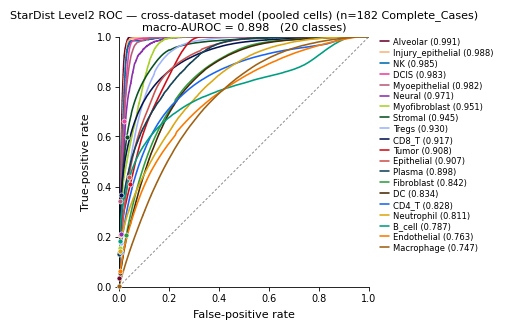

Pooled macro AUROC (L2): 0.8983

=== L12 | discovering validation_external_stardist_matched_AUROC_level12.csv ===
  BRCA__rep1: 157,016 cells, 8 local classes
  CRC__P1CRC: 149,492 cells, 8 local classes
  GBM__P174511_Initial: 35,961 cells, 8 local classes
  GIST__Charvill-94_c009_v001_r001_reg001: 5,257 cells, 8 local classes
  GIST__Charvill-94_c009_v001_r001_reg003: 8,740 cells, 8 local classes
  GIST__Charvill-94_c009_v001_r001_reg012: 6,438 cells, 8 local classes
  GIST__Charvill-94_c009_v001_r001_reg017: 10,997 cells, 8 local classes
  GIST__Charvill-94_c009_v001_r001_reg024: 3,065 cells, 8 local classes
  GIST__Charvill-94_c009_v001_r001_reg026: 5,108 cells, 8 local classes
  GIST__Charvill-94_c009_v001_r001_reg036: 6,472 cells, 8 local classes
  GIST__Charvill-94_c009_v001_r001_reg044: 3,043 cells, 8 local classes
  GIST__Charvill-94_c009_v001_r001_reg045: 9,273 cells, 8 local classes
  GIST__Charvill-94_c009_v001_r001_reg054: 6,648 cells, 8 local classes
  GIST__Charvill-94_c

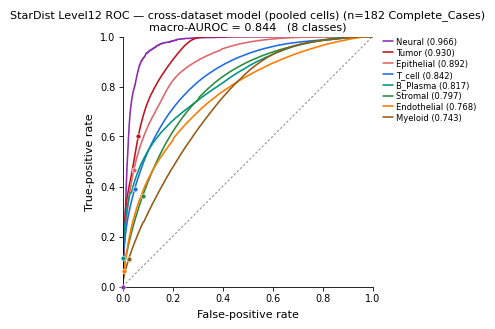

Pooled macro AUROC (L12): 0.8442

=== L1 | discovering validation_external_stardist_matched_AUROC_level1.csv ===
  BRCA__rep1: 157,016 cells, 5 local classes
  CRC__P1CRC: 149,492 cells, 5 local classes
  GBM__P174511_Initial: 35,961 cells, 5 local classes
  GIST__Charvill-94_c009_v001_r001_reg001: 5,257 cells, 5 local classes
  GIST__Charvill-94_c009_v001_r001_reg003: 8,740 cells, 5 local classes
  GIST__Charvill-94_c009_v001_r001_reg012: 6,438 cells, 5 local classes
  GIST__Charvill-94_c009_v001_r001_reg017: 10,997 cells, 5 local classes
  GIST__Charvill-94_c009_v001_r001_reg024: 3,065 cells, 5 local classes
  GIST__Charvill-94_c009_v001_r001_reg026: 5,108 cells, 5 local classes
  GIST__Charvill-94_c009_v001_r001_reg036: 6,472 cells, 5 local classes
  GIST__Charvill-94_c009_v001_r001_reg044: 3,043 cells, 5 local classes
  GIST__Charvill-94_c009_v001_r001_reg045: 9,273 cells, 5 local classes
  GIST__Charvill-94_c009_v001_r001_reg054: 6,648 cells, 5 local classes
  GIST__Charvill-94_c0

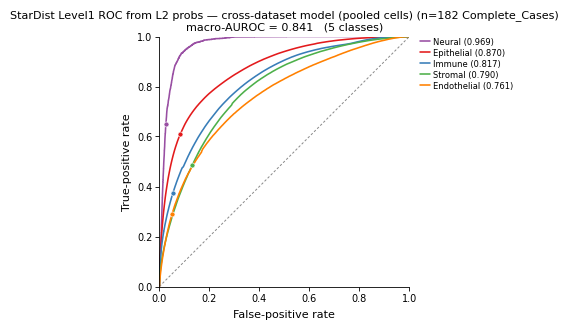

Pooled macro AUROC (L1): 0.8415
A3 best_mlp fold-0 held-out pooled L2 macro AUROC = 0.8983
A3 best_mlp fold-0 held-out pooled L12 macro AUROC = 0.8442
A3 best_mlp fold-0 held-out pooled L1 macro AUROC = 0.8415


In [8]:
from uni_label_cv_helpers import symlink_stardist_sample_dirs

# 2026.10.26, historical fold plan / 与上面的旧 deployment 权重同一套；paired_v2 的 fold_plan 在 result_uni2_A3_..._paired_v2_seed42
plan = pd.read_csv(
    REPO / "data" / "PanCancer" / "result_uni2_A3_adjacent_spatial_k8mean_gate" / "fold_plan.csv"
)
held = plan.loc[plan["fold"].astype(int) == 0]
names = (held["dataset"].astype(str) + "__" + held["sample"].astype(str)).tolist()
missing = [name for name in names if not (A3_ROC / name).is_dir()]
if missing:
    raise FileNotFoundError(f"{len(missing)} fold-0 sections have no ROC dir, e.g. {missing[:3]}")
held_root = A3_PRED / "heldout_fold0_roc"
symlink_stardist_sample_dirs(A3_ROC, names, held_root)
print(f"fold 0 held-out sections: {len(names)}  cells: {int(held['n_keep'].sum()):,}")
held_out = A3_PRED / "pooled_roc_heldout_fold0"
results_a3_held = plot_pooled_stardist_tier_rocs(
    held_root,
    held_out,
    tiers=("l2", "l12", "l1"),
    layout="pooled_stardist",
    pan_organ="pancancer",
    figsize=(2.0, 2.0),
    show_barplot=False,
    save_per_class_csv=True,
    show=True,
)
for tier, rec in results_a3_held.items():
    info = rec.get("roc_info") or {}
    print(f"A3 best_mlp fold-0 held-out pooled {tier.upper()} macro AUROC = {info.get('macro_auc', float('nan')):.4f}")
